# Planning and Acting with Uncertainty

## Games

In this section we will be talking about **non-cooperative multi-agent systems** - reasoning as an agent within a system containing other agents with their own goals, preferences, and reasoning systems. Examples of this would be chess and go, or real-world examples like cybersecurity agents or storefronts. 

Games and agents can be described by **actions** or moves available to each agent; **utility** or payoff functions for each agent, assigning real numbers to outcomes of the game (typically **terminal states**; if utility functions are all the same, the agents copperate); and **strategy** functions for each agent, which assign an action to each agent at each state. 

### Game trees

In *perfect-information games*, where agents can see the state they are in, a **game tree** is a tree with nodes representing states and arcs representing moves between states. Each node is labelled with an agent, the one whose 'turn' it is; each arc coming out of a node represents an action for that agent; each node labelled with **nature** has a probability distribution over its children (not governed by any agent's response); and the leaves, representing final outcomes, are labelled with utilities for each agent. An actual game is a path from the root to a leaf node. 

In a **zero-sum game** (the final utilities sum to zero, e.g. tic-tac-toe), it is sufficient to represent an outcome using one utility. This can be thought of as one agent trying to maximise the utility, and the other trying to minimise it; this is the **minimax** algorithm.

### Minimax

To find the optimal move at each stage:

1. Generate the entire game tree down to the leaves.
2. Apply the utility function to each leaf. 
3. Working back up the game tree, assign values to each internal node - a max node computes the max of its child values, a min node computes the min (if the agent took the optimal move at this node what would be the final payoff). 
4. Now when you play, a max node chooses the action leading to the child with the highest value - a min node chooses the action leading to the child with the lowest value. 

```
def MiniMax-Decision(state):
    return a in Actions(state) maximising Min-Value(Result(a, state)) # for max; minimising if min

def Max-Value(state):
    if state is terminal return Utility(state)
    v = -inf
    for a, s in Successors(state) v = max(v, Min-Value(s))
    return v

def Min-Value(state):
    if state is terminal return Utility(state)
    v = inf
    for a, s in Successors(state) v = min(v, Min-Value(s))
    return v
```

This is reasonable for small state spaces, like tic-tac-toe. For very large state spaces, can use 
- pruning of the game tree (*if an option is bad compared to other available options, no point searching to see exactly how bad*)
- heuristic evaluation of states
- Monte Carlo tree search
- machine learning

### Alpha-Beta pruning

This rests on the idea that if node $n$, a choice for MAX, has a value less than some $m$ on an alternate branch higher up in the tree, it's no use expanding on $n$, as it would never be reached. 

More specifically, we store two parameters $\alpha$ and $\beta$ - $\alpha$ is the highest-value choice found for MAX so far, and $\beta$ is the lowest-value choice found for MIN so far - and prune a branch when $\alpha \geq \beta$, i.e. if you are MAX, you see an option for MIN which is less than the best value you have seen for yourself so far - MIN will choose that value or less, so don't bother looking at the rest of the options, discard this branch. 

Then during search $\alpha$ is updated by `Max-Value` and $\beta$ by `Min-Value`. Note these are local, not global, variables. 

```
def Alpha-Beta-Search(state):
    v = Max-Value(state, -inf, +inf)
    return action in Actions(state) with value v

def Max-Value(state, alpha, beta):
    if state is terminal return Utility(state)
    v = -inf
    for a in Actions(state):
        v = Max(v, Min-Value(Result(state,a), alpha, beta))
        alpha = max(alpha, v)
        if alpha >= beta return v
    return v

def Min-Value(state, alpha, beta):
    if state is terminal return Utility(state)
    v = inf
    for a in Actions(state):
        v = min(v, Max-Value(Result(state,a), alpha, beta))
        beta = min(beta, v)
        if alpha >= beta return v
    return v
```

This:
- gives the same result as minimax
- in the worst case, branches are ordered so that no pruning takes place; no improvement
- in the best case, each player's move is the left-most child
- ordering moves improves the effectiveness of pruning e.g. captures first, then threats, etc.

### Heuristic evaluation functions

These estimate how good a current state is for a player. E.g. value of all white pieces - value of all black pieces. These will be handcrafted by domain experts or learned by machine learning. Typical values are the real numbers or [-1, 1]. If it is +x for one player, it is -x for another. This enables another form of search called **cut-off search** - after a maximum depth is reached, use a heuristic evaluation function instead of actual utility. 

For chess it is typically a weighted sum of features, with weights learned by machine learning algorithms - features can be number of white - black queens, coordinates of specific pieces, number of moves a player can make, pawn structure, etc. 

### Monte-Carlo Tree Search

This is a heuristic search algorithm. It involves four steps: **Selection, Expansion, Simulation**, and **Backpropagation**. It grows a search tree by iteratively *selecting* a node and *expanding* on it; selection balances exploitation and exploitation; random plays are simulated to estimate the value of the node being expanded; *backpropagation* updates the values of nodes based on the simulation outcome. 

### ML

MCTS + Neural networks (e.g. AlphaGo). 

## Probabilistic Inference and Bayesian Networks

### Intro to Probability

Modern ML is all about probability - a classifier that labels an image is actually forming a probability distribution of labels; a LLM is all about training and sampling from a conditional distribution. Any problem relating to making decisions is usually a case of incomplete information and thus, probabilities. Limitations might be theoretical limitations (can't model molecular structure of coin and air movements), measurement limitations (can't measure exactly movement of coin and state of air), or computational limitations (calculations might be too time-consuming even if all this information was available). Models are always simplifications. They can, however, be useful for reasoning about unknown variables, given evidence - e.g. explanation (diagnostic reasoning) or prediction (causal reasoning). 

Blah blah blah probability blah blah. A **joint distribution** over a set of random variables is map from a total assignement to the reals, which must obey $0\leq P\leq 1$ and $\sum P=1$. For $n$ binary variables you will have $2^n$ rows of possible assignments in your table. 

**Marginalisation** is the process of projecting a joint distribution onto a subset of its variables by summing over all the values of the variable being eliminated. 

To get a **conditional distribution**, select the joint probabilities matching that value of the variable being conditioned on ($A\cap B$) and then normalise them (same as dividing by P(B)) to sum to 1. 

### Probabilistic Inference

**Probabilistic inference** is the process of computing a desired probability from known ones. Variables can be **query** (those we want to know information about - e.g. whether bus is on time), **evidence** (those whose values are observed - e.g. weather, date), or **hidden** (value not observed - e.g. roadworks in another part of town). Our beliefs can change with new **evidence**. 

The process is:
1. State what you need: $P(Y_1,\ldots,Y_m\mid e_1,\ldots,e_k)$ and identify query $Y$, evidence $e$, and hidden $H$ variables. 
2. Select the entries of query + hidden + evidence consistent with the evidence. 
3. Sum out H: $P(Y_1,\ldots,Y_m\mid e_1,\ldots,e_k)=\sum_h P(Y_1,\ldots,Y_m,h_1,\ldots,h_r,e_1,\ldots,e_k)$.
4. Normalise the remaining entries. 

This has worst-case time complexity $O(d^n)$ and space complexity $O(d^n)$ to store the entire joint distribution. This is known as the *curse of dimensionality* - as the dimension of our data grows, our space and time complexity grows uncontrollably. Hence, we are often on the lookout for a **simple** and **compact** model, which is easier to build, explain, and perform computations with. One way of measuring the **complexity** of a probabilistic model is to count the number of values that can be specified (the total domain), i.e. for $n$ variables each with domain size $d$, this becomes $d^n$. The number of **free parameters** or total assignments is $d^n-1$. 

We can decrease the number of free parameters by assuming the variables are independent. Then, there are only $n$ free parameters. However, **unconditional** or absolute **independence** is very rare. But **conditional** independence is more common - e.g. $P(x\mid z,y)=P(x\mid z)$. AN example would be having a domain with three variables - the cause, effect 1, and effect 2. Effect 1 is conditionally independent of effect 2 given cause: $P(Effect1\mid Effect2, Cause)=P(Effect1\mid Cause)$. Then the joint becomes $P(Cause, Effect1, Effect2)=P(Effect1\mid Cause)P(Effect2\mid Cause)P(Cause)$. 


### Bayesian Networks

We can use this idea - factorising a complex joint distribution into simpler conditional ones, using conditional independence - to reduce the number of free parameters. The way we represent this is using a **Bayesian network**. 

This consists of one node for each random variable, with arcs between nodes representing direct probabilistic influence, making up a DAG. For each node, you must have a probability distribution given its parents. Given its *parents*, a node is *conditionally independent* of its *non-descendants*. Given its *parents, children, and children's parents* (its **Markov blanekt**), it is conditionally independent of all other nodes in the graph. Hence the joint can be constructed by traversing a graph up to its root. 

### Probabilistic Models

In general, a **probabilistic model** is a model which lets us learn and reason in uncertain settings. It lets us update our beliefs as new observations arrive, and can be used to generate data by sampling. It can be used to answer any probabilistic query about a system.

**Bayesian networks**, as a reminder, are a type of probabilistic model, represented as a DAG, with nodes representing uncertain quantities, arrows representing direct dependence, and each node having conditional distributions given the values of its parents. The joint probability is the product of conditional probabilities down the DAG. 

Though the arrows usually represent a causal relationship, in principle you can always reverse the direction of the arrows, resulting in the same joint distribution but different conditionals, and arrows which no longer represent exact causal relationships. This can be suitable for variables which are simply correlated, rather than having a causal relationship. True causal patterns often result in simpler, interpretable, easy-to-obtain-from-experts BNs; non-causal BNs, however, can encapsulate a domain even if not all variables are causally connected. The arrows just allow dependence. 

The structure of a graph can limit the distributions that can be encoded within it. Adding arcs increases the possible set of distributions by increasing the set of possible dependencies, but comes at a cost; there are more parameters. 

### Naive Bayes

This is a BN topology which assumes there is one class C and all features are conditionally independent of one another given the value of the class. This is obviously not true in most contexts but can simplify computation a lot. 

Then, given the features, we can estimate the class as the class which maximises $P(C\mid X)$ as calculated using Bayes' theorem. (Find $P(C,X)=P(x_1\mid C)\times\ldots\times P(x_n\mid C)$ and normalise).

This assumption allows us to make the most of our data if we directly estimated $P(C\mid X)$, for a particular $X$, we would only be looking at examples for that particular combination of $X$ values - what if our combo is not even observed in the dataset? What if there are only 1 or 2 isntances? However using Naive Bayes, we instead estimate $P(x_1\mid C),P(x_2\mid C)$ etc., using more data for each estimation, and use the result to make predictions. 

Nevertheless, if we don't have any examples of $x_1=a$ with $C=c$, then the entire probability will become $0$, and for *any* future input including $x_1=a$ we will predict $C=c'$ with probability 1. In other words, zero counts in small data sets lead to zero probabilities, which is too strong a claim based on a small sample. 

#### Laplace smoothing

We can fix this issue by adding a positive *pseudo-count* to all the counts, ensuring no probability is 0:

$$P(A=a\mid B=b)\approx \frac{\text{count}(A=a,B=b)+\text{pseudocount}}{\text{count}(B=b)+\text{pseudocount}|\text{domain}(A)|}$$

Where $|\text{domain}(A)|$ is the number of different values $A$ can take.

This smooths the distributions towards a uniform one. The more data you have, the less relevance your pseudo-count of 1 or 2 has and the more confident your probabilites will be; the less data you have, the closer your distributions will be to a uniform. 

### Generative AI

Any time we have a probabilistic model, we can generate data using it via sampling. To sample from a Bayesian Network:
1. Visit each node in order such that each parent comes before its children
2. Find the conditional distribution given the values of parents
3. Sample a value from that distribution and add it to your sample-so-far. 

Repeat for more samples. 

## Intro to Machine Learning

### Overview

**Machine learning** is perhaps the largest sub-field of **artificial intelligence**. With Bayesian netwroks, we saw an example of *learning* - estimating probabilities using data - and *prediction* - using the resulting model to classify a new example. 

**Learning** is the process of improving behaviour (expanded range of behaviour, greater accuracy, greater speed etc.) based on experience. In other words, a **learning problem** can be defined in terms of a **task** (the behaviour being improved), the **data** (experiences used to improve performance in the task), and a **measure of improvement**. 

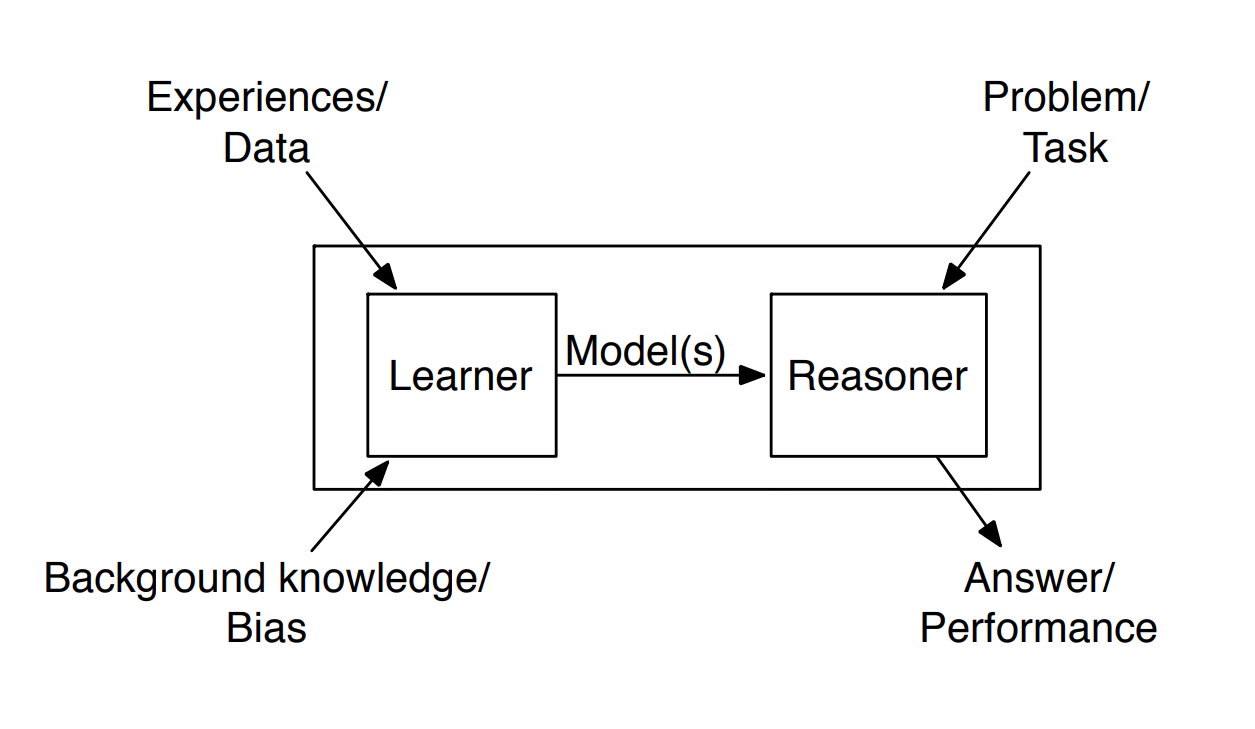


### Supervised Learning Overview

Want to model target features using input features given training examples to minimise loss/error. 

This can be formulated as an **optimisation problem** - we want to search amongst candidate models to find the one that minimises loss. Exhaustive search is often impossible, so we use other methods, like **gradient descent**. Parameters might also be calculated deterministically - e.g. using least squares.

The **training set** is used to fit the model; the **test set** is used to evaluate its predictions on examples not used for fitting (and the **validation set** is not trained on but may be used to tune hyperparameters and make design choices). **Generalisation** is the ability to perform well on unseen examples. **Overfitting** occurs when the model fits to details of the training data that do not generalise, such as noise. 

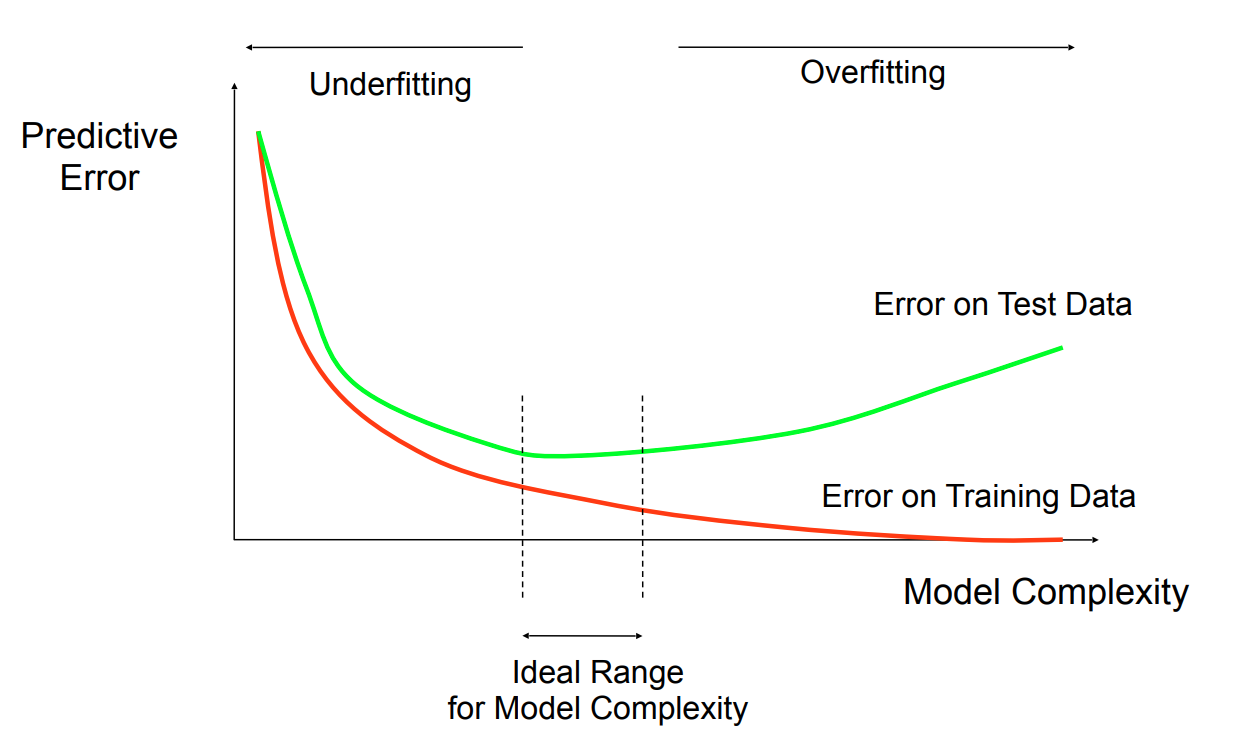

A **parametric model** has a fixed, finite number of parameters - e.g. naive Bayes, linear regression, neural networks with fixed architecture. A **non-parametric model** has a representation which can grow with the training data; e.g. *instance-based methods* (make predictions based on particular instances in the training data), *lazy learning* (delaying computation until the time of prediction). k-NN is an example of this. 

### k-Nearest Neighbours (k-NN)

kNN predicts an output using the output of the nearest training examples, measured by some **distance function**, for example the number of categorical features that differ, or the Euclidean distance. For a particular point, you need to find the radius that will give you k training examples. 

- The training examples are stored as input-output pairs. 
- For a new input, a distance function is used to select the *k* nearest examples, and a **combine function** (e.g. averaging, or finding the most common value) is applied to their outputs to obtain a prediction. 
- *k* is a **hyperparameter**, chosen independently of fitting, and will determine the over- or underfit of your model. 

Require normalised data, as if one feature is much larger than others, it will dominate the distance function. 

### Perceptrons

#### Intro

Inspired by neurons in brains. 

Defined by a set of inputs $x_i$ (other neurons, or pieces of data) each with an assigned weight $w_i$. A linear neuron has a value $a$ which is $a=\sum w_i x_i + b$ where $b$ is some *bias*. It has an *activation function* $g(a)$ which may be for example ReLu or a Heaviside function. Hence in n-dimensional space, $n+1$ parameters are needed to specify a perception - $n$ parameters, plus the bias. 

#### Decision boundaries

Use weight vector to see which side of the boundary will be '1' or '0'. Weight vector will be perpendicular to the line of the decision boundary. 

#### Training

Can use a simple update: weight <- weight + alpha * x * (t-y) and bias <- bias + alpha * (t-y) instead of gradient descent. 

One iteration through the training examples is called an **epoch**. Repeat until an iteration produces no updates, or updates are below some $\epsilon$, or a specified number of epochs have been reached.

If the data are **linearly separable**, the weights will converge to a perfect decision boundary that correctly classifies every data point. 

### Neural Networks and Deep Learning

#### Motivation

Suppose we have data which are not linearly separable; for example a lattice of 0 and 1 data points. Then we can't fit the data with just one perceptron. Instead, we can use two perceptrons. Say $x_1,x_2$ are the input; then we have neurons, $P_1$ and $P_2$, with each individual neuron again beng a line/decision boundary; their output may lead to a decision, 0 or 1 (e.g. 1 if both output 1, 0 otherwise). 

This happens by passing their outputs to a last perceptron. 

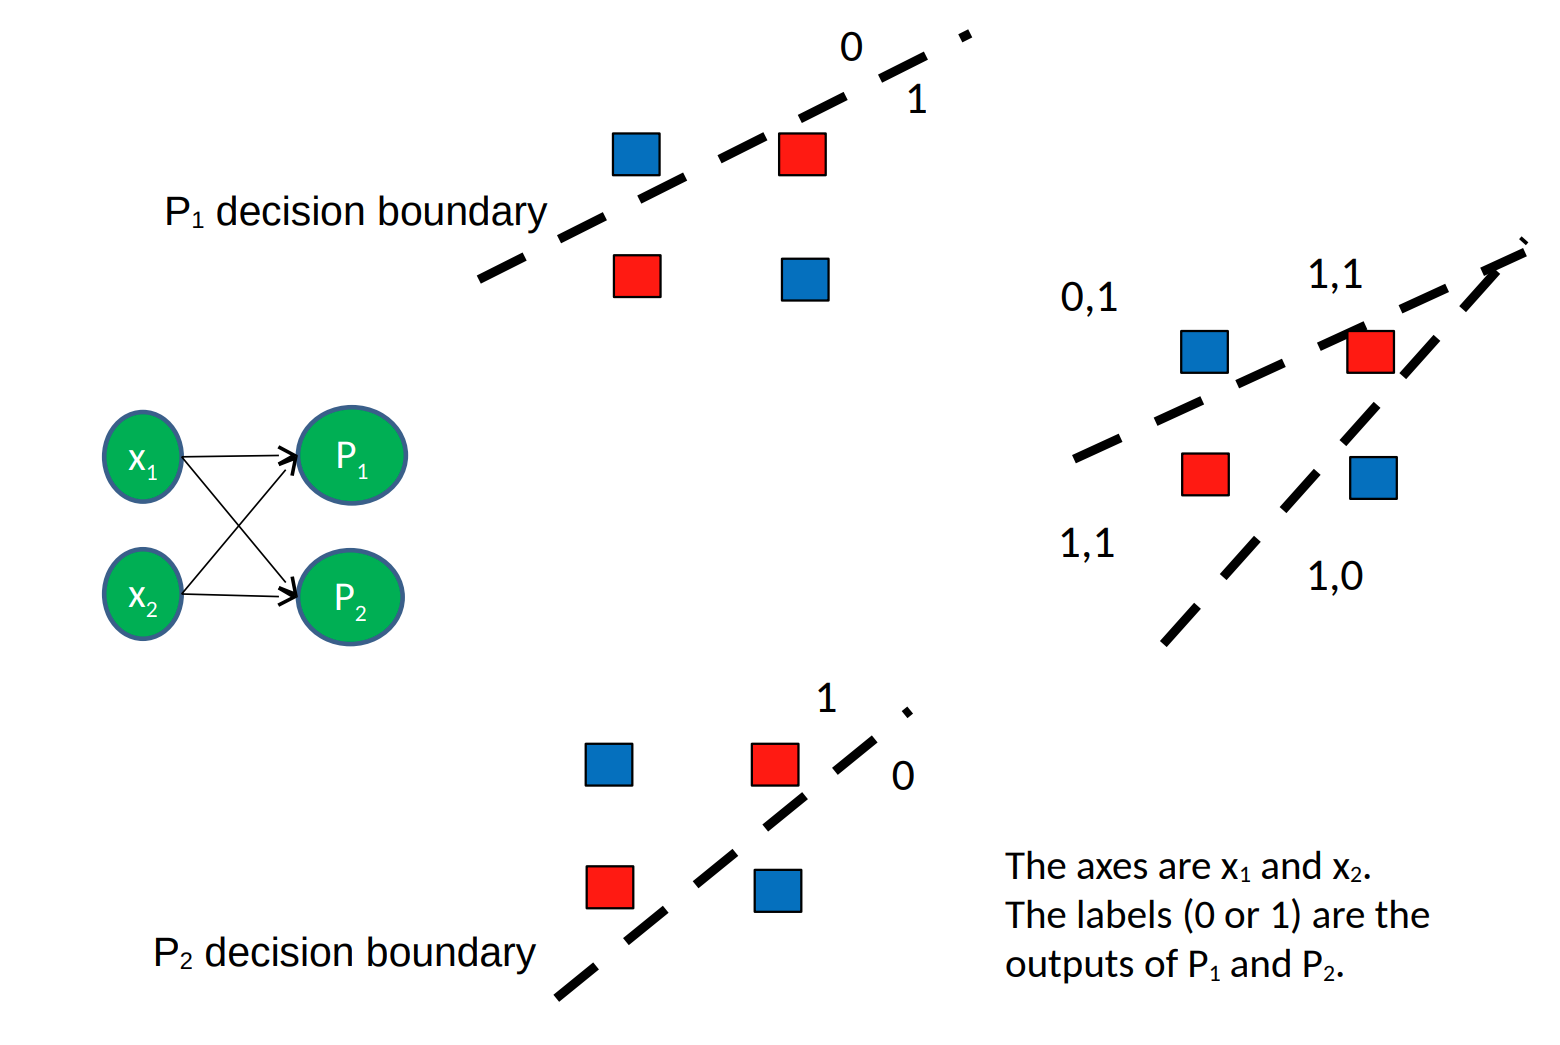

With enough perceptrons, islands and any arbitrary shapes can be represented, with classifications being represented by shapes created by many intersecting lines. More generally, a NN can approximate any continuous function, supports feature learning (learning which features are important), and can capture abstract features (like eyes, nose, etc. in an image) and hierarchical representations (like learning lines -> shapes in an image). 

#### Description

A multi-layer feed-forward NN (meaning data only goes in one direction) is a directed acyclic graph. 

The input must be a vector of real numbers. Even if it's something like an image or text, it must first be converted to a vector of reals. Booleans can be represented using 1 for true and 0 or -1 for false; categorical variables using **indicator variables** (a **one-hot encoding**). 

Then you pass it into a function, for example a complete linear function would be a series of $n$ nodes accepting $m$ input values, and one bias node, therefore outputting one weighted sum value. This is passed into some **activation function**, for example ReLU; this introduces non-linearity. 

In other words, a feed-forward NN implements some function $f(x)=f_n(f_{n-1}(\ldots f(_1(x))))$. Each function $f$ maps an input $\vec{x}$ to another vector, with each neuron being called a **unit**, and the entire function also being called a **layer** - either a **hidden layer** or an **output layer**. The number of functions is the **depth** of the network.

Each (linear) function is $out[j]=\phi(\sum_k in[k]\times w[k,j])$ where $\phi$ is the activation function, $out[j]$ is the $j^{th}$ output neuron, $in[k]$ is the $k^{th}$ input value, and $w[k,j]$ is the weight associated with that input value, for that output unit. Note that there will be an extra input with value 1 which is the bias. The outputs of one layer are the inputs to the next. 

The activation function depends on the type of output. If you are trying to output a real number, optimise **squared loss** and use $\phi(x)=x$ for your output layer. If you are trying to output a Boolean, use **binary cross-entropy loss** with a **sigmoid** for the output layer. If you are outputting a >binary categorical, use **categorical log loss** with a **softmax**; the output layer will have one unit for each category. 

#### Training using backpropagation and gradient descent

The architecture (number and type of layers and units) is fixed, but the model needs to learn the weights. We do this using gradient descent. The basic idea is that you push the weights in the direction of the loss function's (decreasing) gradient. 

You can get the error/loss as a function of the input - $f(e)=f_n(\ldots f_1(x_e))$. Then using the chain rule from calculus, we can derive that the derivative of error wrt some weight $w$ used as part of $f_j$ is $\frac{\partial}{\partial w} f(e) = e'(v_n)\times \frac{\partial}{\partial w} f_n(v_{n-1})\times \ldots \times \frac{\partial}{\partial w}(f_j(v_{j-1}))$. 

So to train the model, you do a **forward pass** - make a prediction using an input - then **back propagate** - update each weight using the derivative of error with respect to it. 